In [1]:
import qlib
from qlib.config import REG_US # [REG_CN, REG_US]

from qlib.data.dataset.loader import QlibDataLoader
from qlib.data.dataset.handler import DataHandler, DataHandlerLP

from qlib.utils import init_instance_by_config
from qlib.workflow import R
from qlib.workflow.record_temp import SignalRecord, PortAnaRecord
from qlib.utils import flatten_dict

import optuna

import pandas as pd
import numpy as np

from pathlib import Path
import sys


p = str(Path().resolve()).split("QuantitativeML_Investing")[0] + "QuantitativeML_Investing"


# Add custom library to path
append_path = p + "\.Lib"
sys.path.append(append_path)


# Init Qlib
provider_uri = p + "\Database\qlib_data_US"  # target_dir
qlib.init(provider_uri=provider_uri, region=REG_US)
print("Qlib version: " + str(qlib.__version__))


print(p)

d:\Projects\Investing\QuantitativeML_Investing\.venv\lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm
[8044:MainThread](2024-05-18 09:19:33,579) INFO - qlib.Initialization - [config.py:416] - default_conf: client.
[8044:MainThread](2024-05-18 09:19:33,664) INFO - qlib.Initialization - [__init__.py:74] - qlib successfully initialized based on client settings.
[8044:MainThread](2024-05-18 09:19:33,679) INFO - qlib.Initialization - [__init__.py:76] - data_path={'__DEFAULT_FREQ': WindowsPath('D:/Projects/Investing/QuantitativeML_Investing/Database/qlib_data_US')}


Qlib version: 0.9.4
D:\Projects\Investing\QuantitativeML_Investing


In [2]:
instruments = 'all'
benchmark = '^GSPC'

In [3]:
###################################
# Define DataLoader
###################################
from furlag_qlib import qdatasets, qfilters

##################################################################################################################
# --------------
# Features
# --------------

fields, names = qdatasets.dataset_features_ts_100()

##################################################################################################################
# --------------
# Labels
# --------------

labels = ['''((EMA(Ref($close, -7), 7) / EMA($close, 7)) - 1)''']

label_names = ['label']

##################################################################################################################
# --------------
# Filters
# --------------

filters = qfilters.Filters()

##################################################################################################################
##################################################################################################################
# ----------------------------
# Initialize data loader
# ----------------------------

data_loader = QlibDataLoader(config={"feature": (fields, names), "label": (labels, label_names)},
                             filter_pipe=filters.us, freq="day")

print(data_loader)
print("Number of features == " + str(len(fields)))

Number of features == 100


In [4]:
###################################
# Define DataHandler
###################################

defined_DataHandler = DataHandlerLP(
    instruments=instruments,
    # start_time='2000-01-01',
    # end_time='2022-01-01',
    data_loader=data_loader,
    infer_processors=[
            # {"class": "ProcessInf", "kwargs": {}},
            # {"class": "ZScoreNorm", "kwargs": {"fit_start_time": '2000-01-01', "fit_end_time": '2016-12-31'}},
            # {"class": "Fillna", "kwargs": {"fields_group": "feature", "fill_value": 0}},
            # {"class": "DropnaProcessor", "kwargs": {'fields_group': 'feature'}},
        ],
    learn_processors=[
            {"class": "DropnaLabel"},
            # {"class": "CSZScoreNorm", "kwargs": {"fields_group": "label"}},
        ]
)


[8044:MainThread](2024-05-18 09:22:27,861) INFO - qlib.timer - [log.py:127] - Time cost: 173.858s | Loading data Done
[8044:MainThread](2024-05-18 09:22:28,726) INFO - qlib.timer - [log.py:127] - Time cost: 0.865s | DropnaLabel Done
[8044:MainThread](2024-05-18 09:22:28,726) INFO - qlib.timer - [log.py:127] - Time cost: 0.865s | fit & process data Done
[8044:MainThread](2024-05-18 09:22:28,726) INFO - qlib.timer - [log.py:127] - Time cost: 174.723s | Init data Done


In [5]:
###################################
# Define task
###################################

task = {
    "model": {
            "class": "LGBModel",
            "module_path": "qlib.contrib.model.gbdt",
            "kwargs": {
                'loss': 'mse',
                'learning_rate': 0.03751318517134016,
                'max_depth': 11,
                'lambda_l1': 1048,
                'lambda_l2': 2635,
                'num_leaves': 4,
                'min_data_in_leaf': 42,
                'feature_fraction': 0.466,
                'bagging_fraction': 0.644,
                'bagging_freq': 7
            },
    },
    "dataset": {
        "class": "DatasetH",
        "module_path": "qlib.data.dataset",
        "kwargs": {
            "handler": defined_DataHandler,
            "segments": {
                "train": ("2000-01-01", "2016-12-31"),
                "valid": ("2017-01-01", "2018-12-31"),
                "test": ("2019-01-01", "2021-12-31"),
            },
        },
    },
}


###################################
# Initialize dataset
###################################

dataset = init_instance_by_config(task["dataset"])

print(dataset)

DatasetH(handler=<qlib.data.dataset.handler.DataHandlerLP object at 0x000002ECFAA349A0>, segments={'train': ('2000-01-01', '2016-12-31'), 'valid': ('2017-01-01', '2018-12-31'), 'test': ('2019-01-01', '2021-12-31')})


In [6]:
###################################
# Hyperparameter tuning
###################################

tune = False


if tune:
    print("Using Optuna to find best parameters...")

    def objective(trial):
        tuning_task = {
            "model": {
                "class": "LGBModel",
                "module_path": "qlib.contrib.model.gbdt",
                "kwargs": {
                    "loss": "mse",
                    
                    "learning_rate": trial.suggest_float("learning_rate", 0.001, 0.1),
                    "max_depth": trial.suggest_int("max_depth", -1, 15),

                    "lambda_l1": trial.suggest_float("lambda_l1", 1e-8, 1e4),
                    "lambda_l2": trial.suggest_float("lambda_l2", 1e-8, 1e4),
                    
                    "num_leaves": trial.suggest_int("num_leaves", 2, 1024),
                    "min_data_in_leaf": trial.suggest_int("min_data_in_leaf", 1, 250),

                    "feature_fraction": trial.suggest_float("feature_fraction", 0.4, 1.0),
                    "bagging_fraction": trial.suggest_float("bagging_fraction", 0.4, 1.0),
                    "bagging_freq": trial.suggest_int("bagging_freq", 1, 7),
                },
            },
        }
        print("Trial params: " + str(tuning_task["model"]["kwargs"]))

        evals_result = dict()
        model = init_instance_by_config(tuning_task["model"])
        model.fit(dataset, evals_result=evals_result, num_boost_round=100000, verbose_eval=100000, early_stopping_rounds=50)

        print("==============================================================================================================================")
        return min(evals_result["valid"])


    study = optuna.create_study(direction='minimize', pruner=optuna.pruners.SuccessiveHalvingPruner())
    '''
    study = optuna.create_study(
        direction='minimize',
        pruner=optuna.pruners.HyperbandPruner(min_resource=1, max_resource=100000, reduction_factor=3)
    )
    '''

    study.optimize(objective, n_jobs=1, n_trials=50, gc_after_trial=True)

    print("Best parameters found:")
    print(study.best_params)

    task["model"]["kwargs"] = study.best_params


In [7]:
###################################
# Train model
###################################


# Model Initialization
model = init_instance_by_config(task["model"])


# start exp to train model
with R.start():
    R.log_params(**flatten_dict(task))
    model.fit(dataset, num_boost_round=1000, verbose_eval=20, early_stopping_rounds=1000)
    
    R.save_objects(trained_model=model)

    rid = R.get_recorder().id


ModuleNotFoundError. CatBoostModel are skipped. (optional: maybe installing CatBoostModel can fix it.)
ModuleNotFoundError. XGBModel is skipped(optional: maybe installing xgboost can fix it).


[8044:MainThread](2024-05-18 09:22:33,848) INFO - qlib.workflow - [exp.py:258] - Experiment 2 starts running ...


ModuleNotFoundError.  PyTorch models are skipped (optional: maybe installing pytorch can fix it).


[8044:MainThread](2024-05-18 09:22:34,366) INFO - qlib.workflow - [recorder.py:341] - Recorder 59443e5fafd14132b753f394cdafe4aa starts running under Experiment 2 ...
[8044:MainThread](2024-05-18 09:22:34,470) INFO - qlib.workflow - [recorder.py:374] - Fail to log the uncommitted code of $CWD(d:\Projects\Investing\QuantitativeML_Investing\Workshop\Test\US) when run git diff.
[8044:MainThread](2024-05-18 09:22:34,533) INFO - qlib.workflow - [recorder.py:374] - Fail to log the uncommitted code of $CWD(d:\Projects\Investing\QuantitativeML_Investing\Workshop\Test\US) when run git status.
[8044:MainThread](2024-05-18 09:22:34,595) INFO - qlib.workflow - [recorder.py:374] - Fail to log the uncommitted code of $CWD(d:\Projects\Investing\QuantitativeML_Investing\Workshop\Test\US) when run git diff --cached.


Training until validation scores don't improve for 1000 rounds
[20]	train's l2: 0.00179394	valid's l2: 0.00090013
[40]	train's l2: 0.00172604	valid's l2: 0.000859245
[60]	train's l2: 0.00169505	valid's l2: 0.000842482
[80]	train's l2: 0.00167953	valid's l2: 0.000834597
[100]	train's l2: 0.00167112	valid's l2: 0.000830749
[120]	train's l2: 0.00166596	valid's l2: 0.000828553
[140]	train's l2: 0.00166311	valid's l2: 0.00082736
[160]	train's l2: 0.00166121	valid's l2: 0.000826619
[180]	train's l2: 0.0016601	valid's l2: 0.000826173
[200]	train's l2: 0.00165949	valid's l2: 0.000825943
[220]	train's l2: 0.00165896	valid's l2: 0.000825746
[240]	train's l2: 0.0016588	valid's l2: 0.000825708
[260]	train's l2: 0.0016586	valid's l2: 0.000825626
[280]	train's l2: 0.0016585	valid's l2: 0.00082559
[300]	train's l2: 0.00165842	valid's l2: 0.000825567
[320]	train's l2: 0.00165828	valid's l2: 0.000825525
[340]	train's l2: 0.00165822	valid's l2: 0.000825501
[360]	train's l2: 0.00165802	valid's l2: 0.0008

[8044:MainThread](2024-05-18 09:23:27,792) INFO - qlib.timer - [log.py:127] - Time cost: 4.230s | waiting `async_log` Done


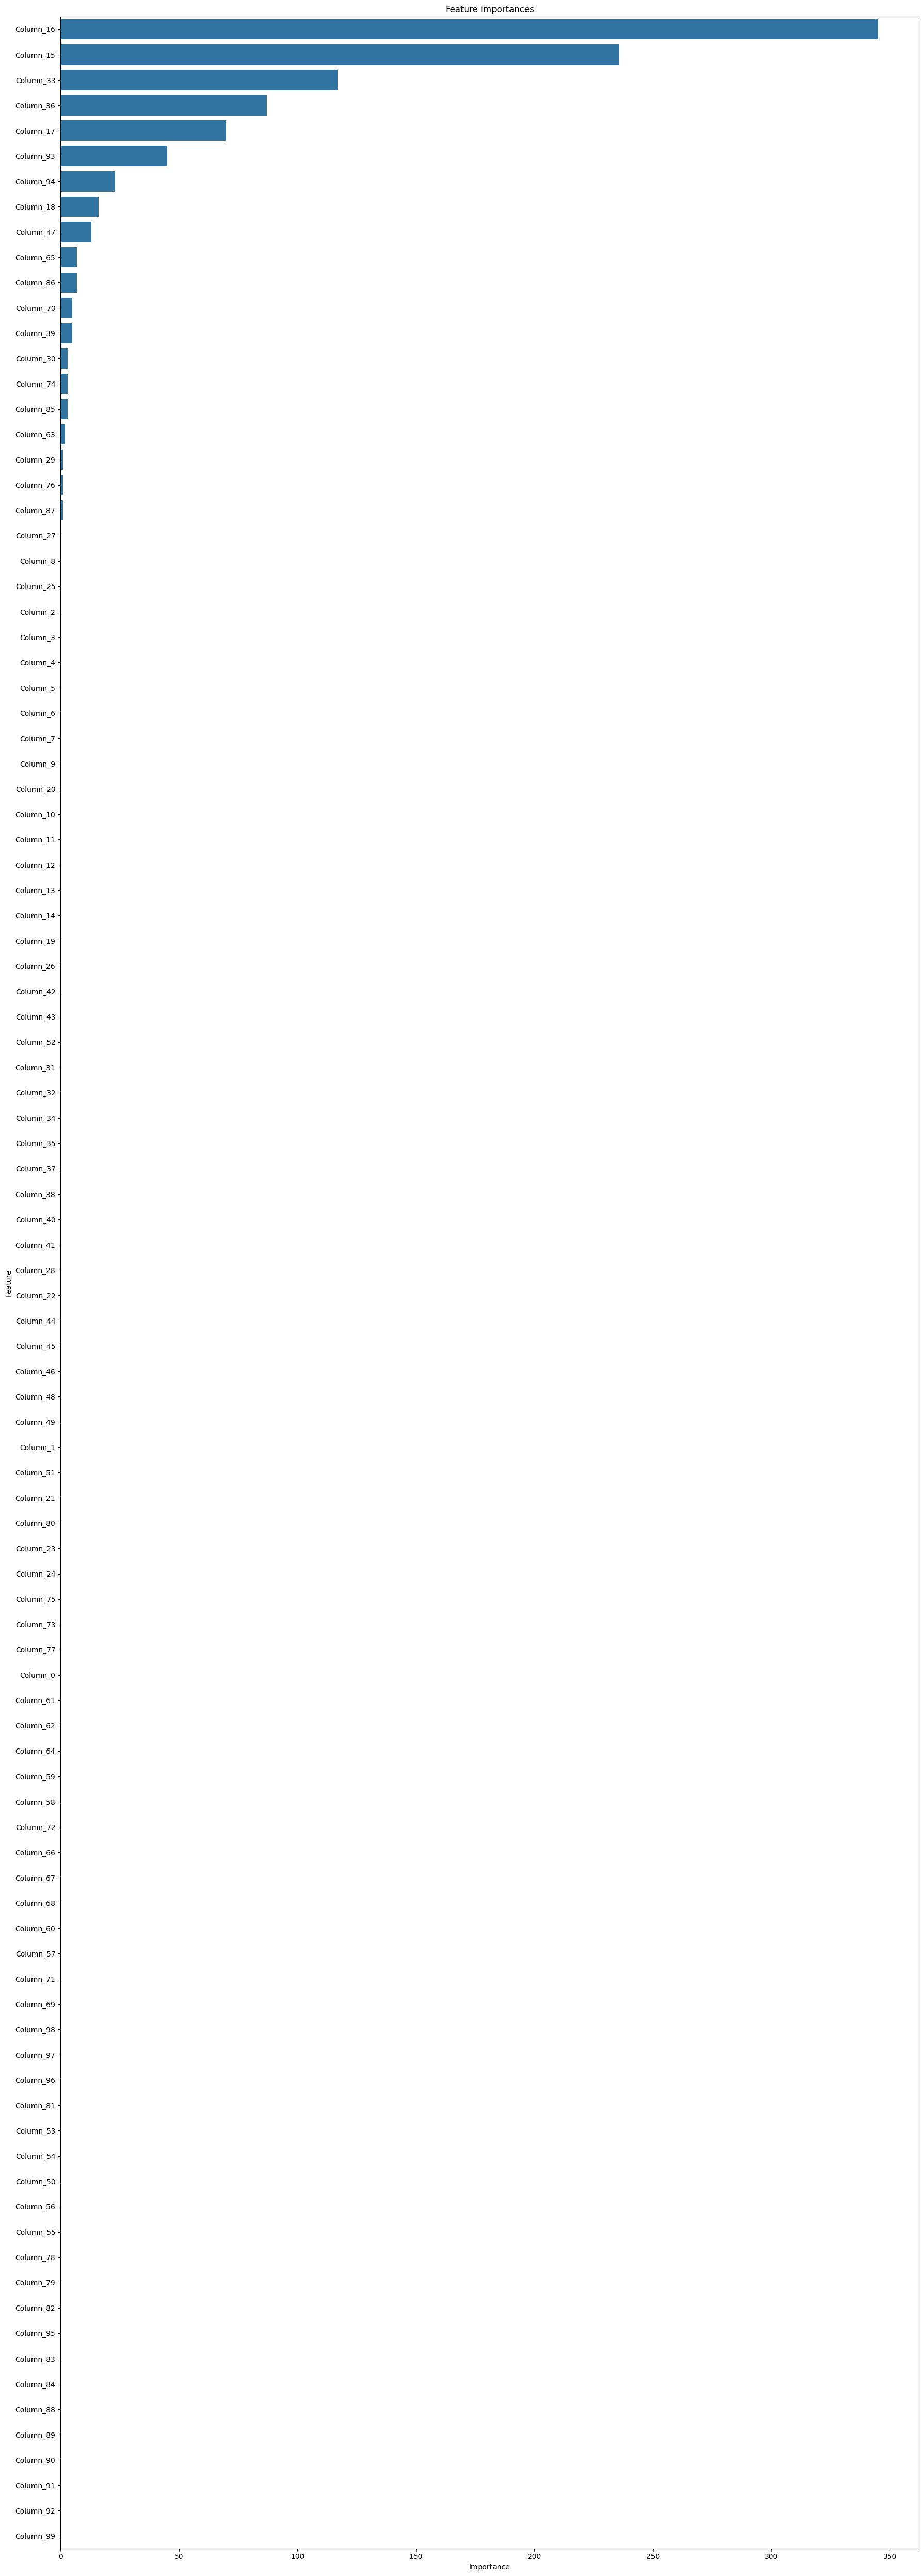

In [8]:
import matplotlib.pyplot as plt
import seaborn as sns


# Get feature importances
feature_importances = model.get_feature_importance()

if len(feature_importances):
    feature_importances = pd.DataFrame({'Feature': feature_importances.index, 'Importance': feature_importances})

    # Display as barplot
    plt.figure(figsize=(18, len(feature_importances) // 2))
    sns.barplot(x="Importance", y="Feature",
                data=feature_importances.sort_values(by="Importance", ascending=False))
    plt.title('Feature Importances')
    plt.tight_layout()
    plt.show()
else:
    print("No feature importances? Something must be wrong...")